## Import Libraries

In [54]:
import requests
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization , Embedding  , SimpleRNN , LSTM , GRU , Dense , Dropout , Input
from tensorflow.keras import regularizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.activations import softmax
from tensorflow.keras.callbacks import EarlyStopping
import joblib

## Load Dataset

dataset link: https://github.com/mhjabreel/CharCnn_Keras/tree/master/data/ag_news_csv


classes: World ,  Sports , Business , Sci/Tech

In [55]:
os.makedirs("ag_news_csv", exist_ok=True)

urls = {
    "train.csv": "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/train.csv",
    "test.csv": "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/test.csv",
    "classes.txt": "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/classes.txt"
}

for filename, url in urls.items():
    response = requests.get(url)
    response.raise_for_status()

    with open(f"ag_news_csv/{filename}", "wb") as f:
        f.write(response.content)

print("Download complete!")

Download complete!


In [56]:
train_path = Path("/content/ag_news_csv/train.csv")
test_path = Path("/content/ag_news_csv/test.csv")

In [57]:
train_df = pd.read_csv(
    train_path,
    header=None,
    names=["label", "title", "text"]
)

test_df = pd.read_csv(
    test_path,
    header=None,
    names=["label", "title", "text"]
)

In [58]:
# Create val set
train_df , val_df = train_test_split(
    train_df , test_size = 0.2 , random_state=42
)

## Explore dataset

In [59]:
train_df.head()

,label,title,text
53541,1,Support independent journalism,Please donate now to our Fall Fund Drive to he...
41728,2,Stingy Falcons Defense Key to 3-0 Start (AP),AP - Maybe the Atlanta Falcons aren't a one-ma...
74819,2,"Pak, Sri Lanka lock horns in Karachi Test today","KARACHI, October 28 (Online): Bruised and batt..."
106459,4,Villages tune in to digital trial,Two villages in Carmarthenshire are the first ...
63062,3,South African gold groups poised for merger,A major re-ordering of South Africa #39;s gold...


In [60]:
val_df.head()

,label,title,text
71787,3,"BBC set for major shake-up, claims newspaper","London - The British Broadcasting Corporation,..."
67218,3,Marsh averts cash crunch,Embattled insurance broker #39;s banks agree t...
54066,2,"Jeter, Yankees Look to Take Control (AP)",AP - Derek Jeter turned a season that started ...
7168,4,Flying the Sun to Safety,When the Genesis capsule comes back to Earth w...
29618,3,Stocks Seen Flat as Nortel and Oil Weigh,NEW YORK (Reuters) - U.S. stocks were set to ...


In [61]:
test_df.head()

,label,title,text
0,3,Fears for T N pension after talks,Unions representing workers at Turner Newall...
1,4,The Race is On: Second Private Team Sets Launc...,"SPACE.com - TORONTO, Canada -- A second\team o..."
2,4,Ky. Company Wins Grant to Study Peptides (AP),AP - A company founded by a chemistry research...
3,4,Prediction Unit Helps Forecast Wildfires (AP),AP - It's barely dawn when Mike Fitzpatrick st...
4,4,Calif. Aims to Limit Farm-Related Smog (AP),AP - Southern California's smog-fighting agenc...


In [62]:
print("Train samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

Train samples: 96000
Validation samples: 24000
Test samples: 7600


In [63]:
train_df.isna().sum()

,0
label,0
title,0
text,0


In [64]:
val_df.isna().sum()

,0
label,0
title,0
text,0


In [65]:
test_df.isna().sum()

,0
label,0
title,0
text,0


Observation: no missing values

In [66]:
train_df.duplicated().sum()

np.int64(0)

In [67]:
val_df.duplicated().sum()

np.int64(0)

In [68]:
test_df.duplicated().sum()

np.int64(0)

Observation: no duplicates

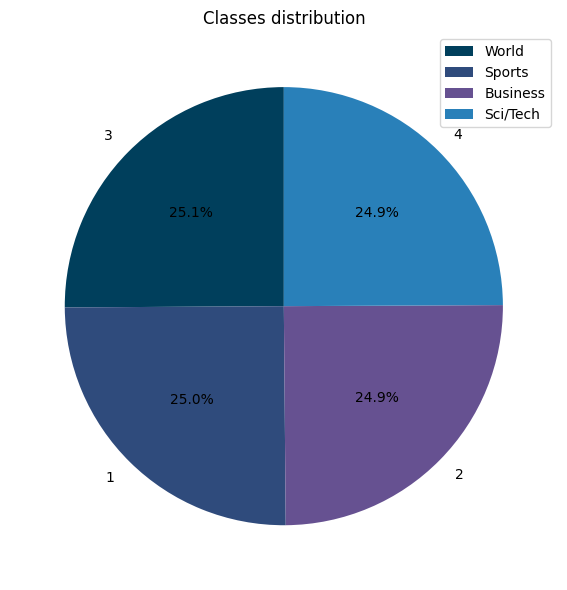

In [69]:
# Show distribution of class
label_count = train_df['label'].value_counts()

plt.figure(figsize=(15,6))
plt.pie(label_count.values , labels = label_count.index ,autopct='%1.1f%%',
startangle=90,colors = ['#003F5C', '#2F4B7C', '#665191', '#2980B9'])
plt.title("Classes distribution")
plt.tight_layout()
plt.legend(['World', 'Sports', 'Business', 'Sci/Tech'])
plt.show()

Observation: dataset is balanced

## Data Cleaning

In [70]:
def text_standarization(text):
  # convert to lowercase
  text = tf.strings.lower(text)

  # remove HTML tags
  text = tf.strings.regex_replace(text , r"<[\s\S]+?>" , " ")

  # remove unnecessary characters
  text = tf.strings.regex_replace(text , r"[^a-zA-Z0-9\s]" , "")

  # normalize extra whitespace
  text = tf.strings.regex_replace(text , r"\s+" , " ")
  text = tf.strings.strip(text)

  return text.numpy().decode("utf-8")

The function cleans and normalizes the input text before vectorization:

* **Lowercase:** Converts all text to lowercase for consistency.
* **Remove HTML tags:** Removes HTML tags such as `<br>` and `<p>`.
* **Remove unnecessary characters:** Keeps only letters, numbers, and whitespace.
* **Normalize whitespace:** Replaces multiple spaces with a single space and removes spaces at the beginning and end.
* **Return text:** Converts the TensorFlow string tensor back to a Python string.

In [71]:
train_df["title"] = train_df["title"].map(text_standarization)
train_df["text"] = train_df["text"].map(text_standarization)

val_df["title"] = val_df["title"].map(text_standarization)
val_df["text"] = val_df["text"].map(text_standarization)

test_df["title"] = test_df["title"].map(text_standarization)
test_df["text"] = test_df["text"].map(text_standarization)

In [72]:
train_df.head()

,label,title,text
53541,1,support independent journalism,please donate now to our fall fund drive to he...
41728,2,stingy falcons defense key to 30 start ap,ap maybe the atlanta falcons arent a oneman te...
74819,2,pak sri lanka lock horns in karachi test today,karachi october 28 online bruised and battered...
106459,4,villages tune in to digital trial,two villages in carmarthenshire are the first ...
63062,3,south african gold groups poised for merger,a major reordering of south africa 39s gold mi...


In [73]:
val_df.head()

,label,title,text
71787,3,bbc set for major shakeup claims newspaper,london the british broadcasting corporation th...
67218,3,marsh averts cash crunch,embattled insurance broker 39s banks agree to ...
54066,2,jeter yankees look to take control ap,ap derek jeter turned a season that started wi...
7168,4,flying the sun to safety,when the genesis capsule comes back to earth w...
29618,3,stocks seen flat as nortel and oil weigh,new york reuters us stocks were set to open ne...


In [74]:
test_df.head()

,label,title,text
0,3,fears for t n pension after talks,unions representing workers at turner newall s...
1,4,the race is on second private team sets launch...,spacecom toronto canada a secondteam of rocket...
2,4,ky company wins grant to study peptides ap,ap a company founded by a chemistry researcher...
3,4,prediction unit helps forecast wildfires ap,ap its barely dawn when mike fitzpatrick start...
4,4,calif aims to limit farmrelated smog ap,ap southern californias smogfighting agency we...


## Configurations

In [75]:
MAX_TOKENS = 20000
SEQ_LEN    = 200
EMBED_DIM  = 300
BATCH_SIZE = 64

## Text Vectorization

In [76]:
# Text -> ID's
title_vectorizer = TextVectorization(
    max_tokens = MAX_TOKENS,
    output_mode='int',
    output_sequence_length = SEQ_LEN
)

text_vectorizer = TextVectorization(
    max_tokens = MAX_TOKENS,
    output_mode='int',
    output_sequence_length = SEQ_LEN
)

In [77]:
title_vectorizer.adapt(train_df['title'])
text_vectorizer.adapt(train_df['text'])

In [78]:
title_voc = title_vectorizer.get_vocabulary()
text_voc = text_vectorizer.get_vocabulary()

print(f"Title voc : {title_voc}")
print(f"Text voc : {text_voc}")

Title voc : ['', '[UNK]', np.str_('to'), np.str_('in'), np.str_('for'), np.str_('on'), np.str_('of'), np.str_('ap'), np.str_('the'), np.str_('39s'), np.str_('us'), np.str_('a'), np.str_('reuters'), np.str_('at'), np.str_('with'), np.str_('new'), np.str_('as'), np.str_('39'), np.str_('up'), np.str_('and'), np.str_('ltbgtltbgt'), np.str_('oil'), np.str_('says'), np.str_('over'), np.str_('microsoft'), np.str_('iraq'), np.str_('by'), np.str_('is'), np.str_('from'), np.str_('after'), np.str_('afp'), np.str_('out'), np.str_('no'), np.str_('deal'), np.str_('stocks'), np.str_('china'), np.str_('profit'), np.str_('more'), np.str_('may'), np.str_('be'), np.str_('update'), np.str_('win'), np.str_('wins'), np.str_('not'), np.str_('talks'), np.str_('world'), np.str_('sales'), np.str_('it'), np.str_('bush'), np.str_('report'), np.str_('prices'), np.str_('back'), np.str_('game'), np.str_('ibm'), np.str_('first'), np.str_('un'), np.str_('security'), np.str_('will'), np.str_('its'), np.str_('off'), np.

In [79]:
X_train_title = title_vectorizer(train_df["title"])
X_train_text = text_vectorizer(train_df["text"])

y_train = train_df["label"]

In [80]:
X_val_title = title_vectorizer(val_df["title"])
X_val_text = text_vectorizer(val_df["text"])

y_val = val_df["label"]

In [81]:
X_test_title = title_vectorizer(test_df["title"])
X_test_text = text_vectorizer(test_df["text"])

y_test = test_df["label"]

In [82]:
X_train = tf.concat([X_train_title, X_train_text], axis=1)
X_val = tf.concat([X_val_title, X_val_text], axis=1)
X_test = tf.concat([X_test_title, X_test_text], axis=1)

In [83]:
X_train.shape

TensorShape([96000, 400])

In [84]:
X_val.shape

TensorShape([24000, 400])

In [85]:
X_test.shape

TensorShape([7600, 400])

In [86]:
# To handle nan in loss
y_train = y_train - 1
y_val = y_val - 1
y_test = y_test - 1

In [87]:
# Improve performance
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
).batch(BATCH_SIZE).cache().prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
).batch(BATCH_SIZE).cache().prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
).batch(BATCH_SIZE).cache().prefetch(tf.data.AUTOTUNE)

### Why Padding and Truncation?

Text samples usually have different lengths, but neural networks require tensors with consistent dimensions within a batch.

- **Padding:** Short sequences are filled with `0`s until they reach the required sequence length.
- **Truncation:** Long sequences are cut to the required sequence length.

Therefore, using `output_sequence_length=200` ensures that the final representation has the shape:

`(batch_size, sequence_length)`

For example:

`(32, 200)`

where `32` is the batch size and `200` is the fixed number of tokens per sequence.

## Embedding

In [88]:
def create_embedding():
    return Embedding(
        input_dim=MAX_TOKENS,
        output_dim=EMBED_DIM,
        mask_zero=True
    )

The `Embedding` layer converts integer token IDs into dense vectors.

* **embedding_dim**: The number of dimensions in each token's vector.

## Model 1 — Simple RNN

In [89]:
def rnn_build(embedding):
  model = Sequential([
      Input(shape=(SEQ_LEN,)),
      embedding,

      SimpleRNN(256, return_sequences=True),
      Dropout(0.3),

      SimpleRNN(128, return_sequences=True),
      Dropout(0.2),

      SimpleRNN(64, return_sequences=True),
      Dropout(0.1),

      SimpleRNN(32, return_sequences=False),
      Dropout(0.1),

      Dense(4 , activation=softmax)
  ], name = "SimpleRNN")

  return model

In [90]:
rnn_model = rnn_build(create_embedding())

rnn_model.compile(
      optimizer = "adam",
      loss = SparseCategoricalCrossentropy(),
      metrics = ["accuracy"]
)

rnn_model.summary()

Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 200, 300)       │     6,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_8 (SimpleRNN)        │ (None, 200, 256)       │       142,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 200, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_9 (SimpleRNN)        │ (None, 200, 128)       │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 200, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_10 (SimpleRNN)       │ (None, 200, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 200, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_11 (SimpleRNN)       │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,207,460 (23.68 MB)

 Trainable params: 6,207,460 (23.68 MB)

 Non-trainable params: 0 (0.00 B)

## Model 2 — LSTM


In [91]:
def lstm_build(embedding):
    model = Sequential([
        Input(shape=(SEQ_LEN,)),
        embedding,

        LSTM(16, return_sequences=False, use_cudnn=False),
        Dropout(0.81),

        Dense(4, activation="softmax" , kernel_regularizer=regularizers.l2(0.01))
    ], name="LSTM")

    return model

In [92]:
lstm_model = lstm_build(create_embedding())

lstm_model.compile(
      optimizer = "adam",
      loss = SparseCategoricalCrossentropy(),
      metrics = ["accuracy"]
)

lstm_model.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, 200, 300)       │     6,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 16)             │        20,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,020,356 (22.97 MB)

 Trainable params: 6,020,356 (22.97 MB)

 Non-trainable params: 0 (0.00 B)

## Model 3 — GRU

In [93]:
def gru_build(embedding):
    model = Sequential([
        Input(shape=(SEQ_LEN,)),
        embedding,

        GRU(32, return_sequences=False, use_cudnn=False),
        Dropout(0.83),

        Dense(4, activation="softmax" , kernel_regularizer=regularizers.l2(0.01))
    ], name="GRU")

    return model

In [94]:
gru_model = gru_build(create_embedding())

gru_model.compile(
      optimizer = "adam",
      loss = SparseCategoricalCrossentropy(),
      metrics = ["accuracy"]
)

gru_model.summary()

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ (None, 200, 300)       │     6,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │        32,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,032,196 (23.01 MB)

 Trainable params: 6,032,196 (23.01 MB)

 Non-trainable params: 0 (0.00 B)

## Training

In [95]:
early_stop = EarlyStopping(
    monitor="val_loss", patience=5 , restore_best_weights=True
  )

In [96]:
rnn_history = rnn_model.fit(
    train_ds,
    batch_size = BATCH_SIZE,
    epochs = 25,
    callbacks = early_stop,
    validation_data = (val_ds)
)

Epoch 1/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 222s 141ms/step - accuracy: 0.2545 - loss: 1.4239 - val_accuracy: 0.2740 - val_loss: 1.3838
Epoch 2/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 209s 140ms/step - accuracy: 0.2678 - loss: 1.3900 - val_accuracy: 0.2777 - val_loss: 1.3843
Epoch 3/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 210s 140ms/step - accuracy: 0.2641 - loss: 1.3867 - val_accuracy: 0.2694 - val_loss: 1.3875
Epoch 4/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 210s 140ms/step - accuracy: 0.2699 - loss: 1.3844 - val_accuracy: 0.2695 - val_loss: 1.3861
Epoch 5/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 211s 140ms/step - accuracy: 0.2694 - loss: 1.3841 - val_accuracy: 0.2707 - val_loss: 1.3868
Epoch 6/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 211s 140ms/step - accuracy: 0.2693 - loss: 1.3843 - val_accuracy: 0.2701 - val_loss: 1.3868


In [97]:
lstm_history = lstm_model.fit(
    train_ds,
    batch_size = BATCH_SIZE,
    epochs = 25,
    callbacks = early_stop,
    validation_data = (val_ds)
)

Epoch 1/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 72s 44ms/step - accuracy: 0.7271 - loss: 0.7745 - val_accuracy: 0.8858 - val_loss: 0.4416
Epoch 2/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 65s 44ms/step - accuracy: 0.7990 - loss: 0.5995 - val_accuracy: 0.8929 - val_loss: 0.4037
Epoch 3/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 66s 44ms/step - accuracy: 0.8087 - loss: 0.5458 - val_accuracy: 0.8950 - val_loss: 0.3875
Epoch 4/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 66s 44ms/step - accuracy: 0.8194 - loss: 0.5000 - val_accuracy: 0.8931 - val_loss: 0.3903
Epoch 5/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 65s 44ms/step - accuracy: 0.8214 - loss: 0.4764 - val_accuracy: 0.8945 - val_loss: 0.3936
Epoch 6/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 65s 44ms/step - accuracy: 0.8280 - loss: 0.4494 - val_accuracy: 0.8930 - val_loss: 0.3988
Epoch 7/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 66s 44ms/step - accuracy: 0.8292 - loss: 0.4329 - val_accuracy: 0.8913 - val_loss: 0.4066
Epoch 8/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 66s 44ms/step - accuracy: 0.8369 -

In [98]:
gru_history = gru_model.fit(
    train_ds,
    batch_size = BATCH_SIZE,
    epochs = 25,
    callbacks = early_stop,
    validation_data = (val_ds)
)

Epoch 1/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 78s 49ms/step - accuracy: 0.7775 - loss: 0.6719 - val_accuracy: 0.8941 - val_loss: 0.3731
Epoch 2/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 72s 48ms/step - accuracy: 0.8850 - loss: 0.4389 - val_accuracy: 0.8962 - val_loss: 0.3617
Epoch 3/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 72s 48ms/step - accuracy: 0.9057 - loss: 0.3735 - val_accuracy: 0.8910 - val_loss: 0.3781
Epoch 4/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 72s 48ms/step - accuracy: 0.9176 - loss: 0.3351 - val_accuracy: 0.8885 - val_loss: 0.4021
Epoch 5/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 73s 48ms/step - accuracy: 0.9265 - loss: 0.2980 - val_accuracy: 0.8852 - val_loss: 0.4270
Epoch 6/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 72s 48ms/step - accuracy: 0.9324 - loss: 0.2775 - val_accuracy: 0.8849 - val_loss: 0.4455
Epoch 7/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 72s 48ms/step - accuracy: 0.9372 - loss: 0.2572 - val_accuracy: 0.8831 - val_loss: 0.4708


## Evaluation

In [99]:
rnn_loss, rnn_acc = rnn_model.evaluate(test_ds)

print(f"Simple RNN Train Accuracy: {rnn_history.history['accuracy'][-1] * 100:.2f}%")
print(f"Simple RNN Val Accuracy: {rnn_history.history['val_accuracy'][-1] * 100:.2f}%")
print(f"Simple RNN Test Accuracy: {rnn_acc * 100:.2f}%")

print(f"\nSimple RNN Train Loss: {rnn_history.history['loss'][-1]:.4f}")
print(f"Simple RNN Val Loss: {rnn_history.history['val_loss'][-1]:.4f}")
print(f"Simple RNN Test Loss: {rnn_loss:.4f}")

119/119 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.2812 - loss: 1.3826
Simple RNN Train Accuracy: 26.93%
Simple RNN Val Accuracy: 27.01%
Simple RNN Test Accuracy: 28.12%

Simple RNN Train Loss: 1.3843
Simple RNN Val Loss: 1.3868
Simple RNN Test Loss: 1.3826


In [100]:
lstm_loss , lstm_acc = lstm_model.evaluate(test_ds)

print(f"LSTM Train Accuracy: {lstm_history.history['accuracy'][-1] * 100:.2f}%")
print(f"LSTM Val Accuracy: {lstm_history.history['val_accuracy'][-1] * 100:.2f}%")
print(f"LSTM Test Accuracy: {lstm_acc * 100:.2f}%")

print(f"\nLSTM Train Loss: {lstm_history.history['loss'][-1]:.4f}")
print(f"LSTM Val Loss: {lstm_history.history['val_loss'][-1]:.4f}")
print(f"LSTM Test Loss: {lstm_loss:.4f}")

119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8909 - loss: 0.3982
LSTM Train Accuracy: 83.69%
LSTM Val Accuracy: 87.80%
LSTM Test Accuracy: 89.09%

LSTM Train Loss: 0.4158
LSTM Val Loss: 0.4581
LSTM Test Loss: 0.3982


In [101]:
gru_loss , gru_acc = gru_model.evaluate(test_ds)

print(f"GRU Train Accuracy: {gru_history.history['accuracy'][-1] * 100:.2f}%")
print(f"GRU Val Accuracy: {gru_history.history['val_accuracy'][-1] * 100:.2f}%")
print(f"GRU Test Accuracy: {gru_acc * 100:.2f}%")

print(f"\nGRU Train Loss: {gru_history.history['loss'][-1]:.4f}")
print(f"GRU Val Loss: {gru_history.history['val_loss'][-1]:.4f}")
print(f"GRU Test Loss: {gru_loss:.4f}")

119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8941 - loss: 0.3740
GRU Train Accuracy: 93.72%
GRU Val Accuracy: 88.31%
GRU Test Accuracy: 89.41%

GRU Train Loss: 0.2572
GRU Val Loss: 0.4708
GRU Test Loss: 0.3740


| Model | Train Acc | Val Acc | Test Acc | Train Loss | Val Loss | Test Loss |
|---|---|---|---|---|---|---|
| Simple RNN | 26.93% | 27.01% | 28.12% | 1.3843 | 1.3868 | 1.3826 |
| LSTM | 83.69% | 87.80% | 89.09% | 0.4158 | 0.4581 | 0.3982 |
| GRU | 93.72% | 88.31% | 89.41% | 0.2572 | 0.4708 | 0.3740 |

**Why LSTM over GRU:** The accuracy difference is tiny (89.09% vs 89.41%, ~0.3 points — basically noise). But GRU overfits more (train 93.72% vs val 88.31%, a 5.4-point gap), while LSTM's train/val accuracy stay close together, meaning it generalizes better. LSTM is also the model the assignment specifically requires comparing against Simple RNN, so it's the natural one to save as the deliverable.

## Save best model

In [102]:
joblib.dump(lstm_model,"best_model.pickle")

['best_model.pickle']